# 02 — Analysis

**Goal:** answer the key questions defined in the Ask phase, using the clean dataset.
**Input:** `data/processed/madagascar_climate_daily.csv`

1. Climate profile of each city
2. Temperature trends
3. Rainfall and rainy season
4. Extremes
5. Risks for people: rain reliability, drought, dangerous heat
6. Comparison between regions

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_PATH = Path("../data/processed/madagascar_climate_daily.csv")
FIG_DIR = Path("../figures")

# Cities from north to south, so every table and chart uses the same order
CITY_ORDER = ["antsiranana", "mahajanga", "toamasina", "antananarivo", "fianarantsoa", "toliara"]

sns.set_theme(style="whitegrid", palette="colorblind")

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df.shape

(98616, 13)

## 1. Climate profile of each city
Average conditions over 1981–2025: temperatures and humidity (NASA POWER), annual rainfall and number of rainy days ≥ 1 mm (CHIRPS).

In [7]:
profile = df.groupby("city").agg(
    mean_temp=("T2M", "mean"),
    mean_tmax=("T2M_MAX", "mean"),
    mean_tmin=("T2M_MIN", "mean"),
    record_tmax=("T2M_MAX", "max"),
    record_tmin=("T2M_MIN", "min"),
    mean_humidity=("RH2M", "mean"),
)

yearly = df.groupby(["city", "year"]).agg(
    rain_mm=("rain_chirps", "sum"),
    rainy_days=("rain_chirps", lambda s: (s >= 1).sum()),
)
profile["annual_rain_mm"] = yearly["rain_mm"].groupby("city").mean()
profile["rainy_days_per_year"] = yearly["rainy_days"].groupby("city").mean()

profile.loc[CITY_ORDER].round(1)

,mean_temp,mean_tmax,mean_tmin,record_tmax,record_tmin,mean_humidity,annual_rain_mm,rainy_days_per_year
city,,,,,,,,
antsiranana,25.0,28.5,22.5,34.6,16.5,79.0,1156.0,65.6
mahajanga,26.8,29.0,24.6,34.5,18.5,73.3,1469.7,80.3
toamasina,23.6,25.6,22.1,33.1,16.1,82.2,3270.6,138.5
antananarivo,16.3,21.4,12.4,29.6,3.2,85.7,1321.8,83.7
fianarantsoa,17.8,23.1,13.7,34.0,3.0,83.7,1150.9,81.2
toliara,25.4,30.4,21.4,39.8,12.4,66.8,311.6,35.3


**Observations.** Madagascar's six cities have very different climates. The east coast is by far the wettest: Toamasina receives about 3,270 mm of rain per year over 138 rainy days, while semi-arid Toliara receives only about 310 mm over 35 days — ten times less rain and four times fewer rainy days. Altitude makes the Highlands much cooler: Antananarivo (16.3 °C) and Fianarantsoa (17.8 °C) are 6 to 10 °C cooler than the coastal cities, with nights dropping to 3 °C. Toliara combines the harshest conditions, with the highest average maximum (30.4 °C), the heat record (39.8 °C) and the driest air (67 % humidity).

**Caution.** NASA POWER temperatures are averages over large grid cells: Antananarivo's mean (16.3 °C) is about 2.5 °C below station normals (about 18.9 °C) because the cell is higher than the city. Absolute levels should be read with care, but trends over time remain valid.

## 2. Monthly normals (1991–2020)
A climate "normal" is the average value for each month over a 30-year reference period. 1991–2020 is the current standard period used by weather services.

In [8]:
ref = df[df["year"].between(1991, 2020)]

monthly = ref.groupby(["city", "year", "month"]).agg(
    rain=("rain_chirps", "sum"),
    tmean=("T2M", "mean"),
    tmax=("T2M_MAX", "mean"),
    tmin=("T2M_MIN", "mean"),
)
normals = monthly.groupby(["city", "month"]).mean()
normals.loc["antananarivo"].round(1)

,rain,tmean,tmax,tmin
month,,,,
1,438.1,19.1,23.5,15.6
2,299.1,19.0,23.3,15.5
3,141.7,18.5,22.9,15.0
4,33.8,17.3,22.0,13.6
5,12.2,15.4,20.4,11.8
6,3.0,13.1,18.0,9.6
7,2.8,12.2,17.0,8.8
8,4.3,12.9,18.4,8.9
9,6.9,14.6,20.7,9.9


In [9]:
MONTH_ORDER = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
MONTH_LETTERS = ["J", "A", "S", "O", "N", "D", "J", "F", "M", "A", "M", "J"]
RAIN_COLOR = "#2a78d6"
TEMP_COLOR = "#eb6834"
NOTE_COLOR = "#52514e"

FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})

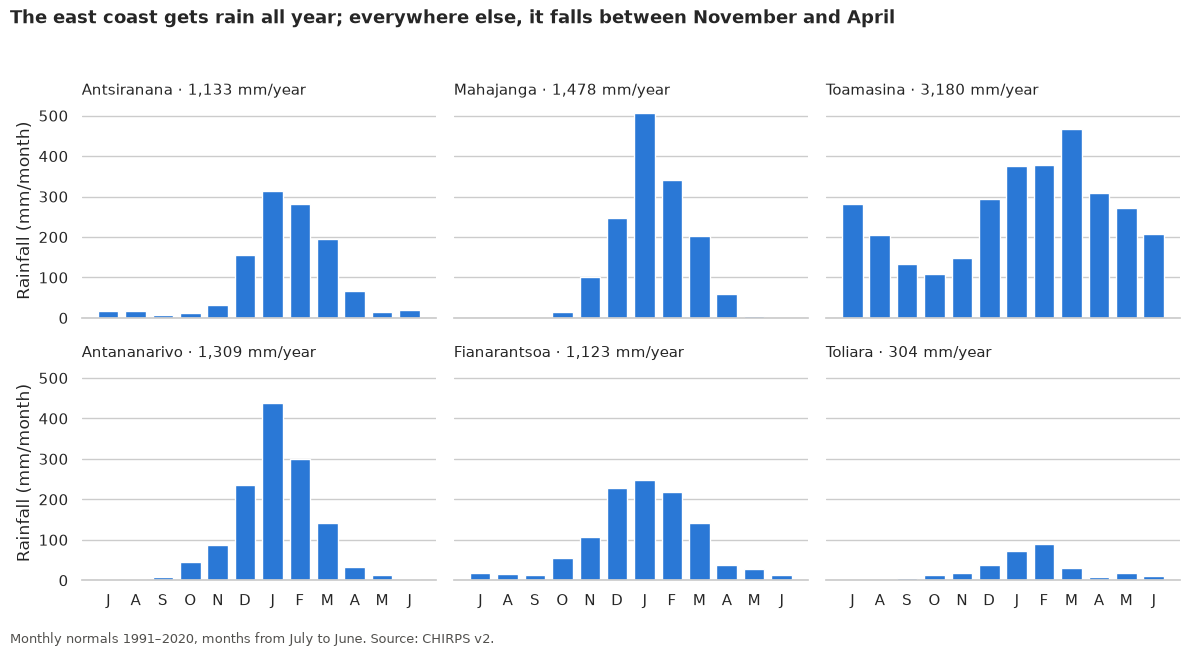

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)

for ax, city in zip(axes.flat, CITY_ORDER):
    data = normals.loc[city].reindex(MONTH_ORDER)
    ax.bar(range(12), data["rain"], color=RAIN_COLOR, width=0.75)
    ax.set_title(f"{city.capitalize()} · {data['rain'].sum():,.0f} mm/year", loc="left", fontsize=11)
    ax.set_xticks(range(12), MONTH_LETTERS)
    sns.despine(ax=ax, left=True)

for ax in axes[:, 0]:
    ax.set_ylabel("Rainfall (mm/month)")

fig.suptitle("The east coast gets rain all year; everywhere else, it falls between November and April",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.005, "Monthly normals 1991–2020, months from July to June. Source: CHIRPS v2.",
         fontsize=9, color=NOTE_COLOR)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(FIG_DIR / "01_rainfall_normals.png", dpi=200, bbox_inches="tight")
plt.show()

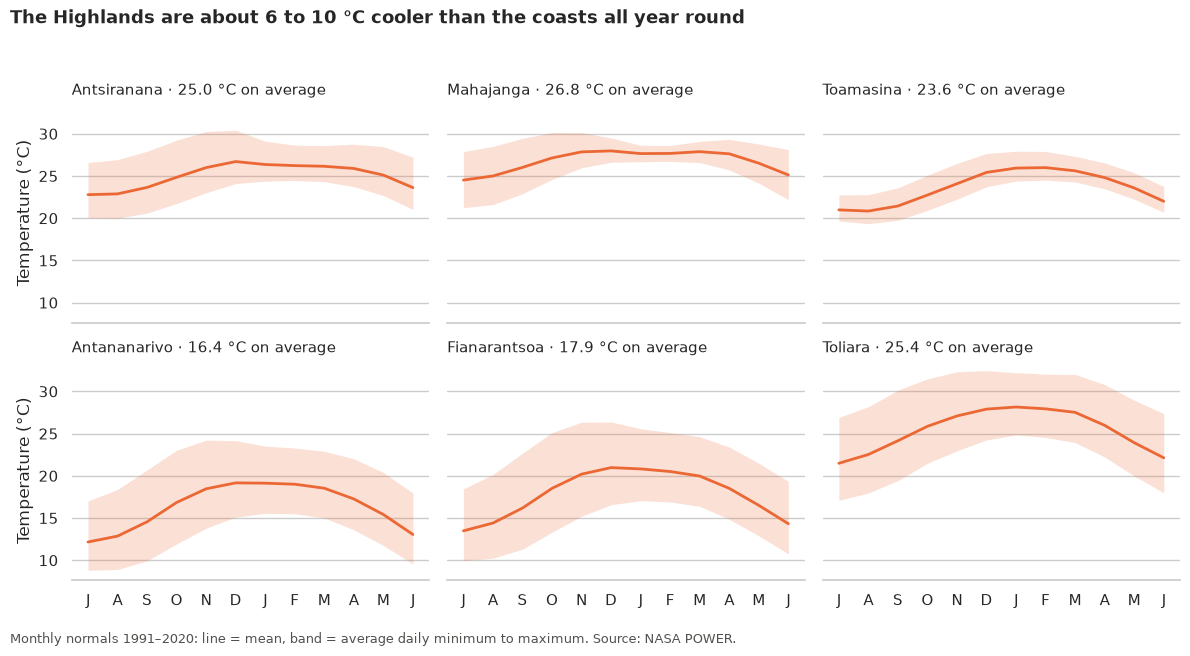

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)

for ax, city in zip(axes.flat, CITY_ORDER):
    data = normals.loc[city].reindex(MONTH_ORDER)
    ax.fill_between(range(12), data["tmin"], data["tmax"], color=TEMP_COLOR, alpha=0.2, linewidth=0)
    ax.plot(range(12), data["tmean"], color=TEMP_COLOR, linewidth=2)
    ax.set_title(f"{city.capitalize()} · {data['tmean'].mean():.1f} °C on average", loc="left", fontsize=11)
    ax.set_xticks(range(12), MONTH_LETTERS)
    sns.despine(ax=ax, left=True)

for ax in axes[:, 0]:
    ax.set_ylabel("Temperature (°C)")

fig.suptitle("The Highlands are about 6 to 10 °C cooler than the coasts all year round",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.005, "Monthly normals 1991–2020: line = mean, band = average daily minimum to maximum. Source: NASA POWER.",
         fontsize=9, color=NOTE_COLOR)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(FIG_DIR / "02_temperature_normals.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations.** Rainfall seasonality differs sharply between regions. Toamasina, on the east coast, receives more than 100 mm even in its driest month, while every other city gets almost all its rain between November and April. Mahajanga has the most concentrated season (about 500 mm in January, almost nothing from May to October), so a late start of the rains matters most there; Toliara's rainy season is barely visible. Temperatures follow altitude: the Highlands are about 6 to 10 °C cooler than the coasts all year round, and they, like Toliara, have a wide gap between day and night (about 10 °C), whereas the ocean keeps Toamasina's daily range narrow (about 5 °C).